# Liver disease risk model (ILPD)

Source: UCI Indian Liver Patient Dataset (id 225). 583 patients from north-east Andhra Pradesh.
Inputs: a standard liver function test, plus age and sex.

| Column | Meaning | MedTrail test name |
|---|---|---|
| TB | Total bilirubin (mg/dL) | Total Bilirubin |
| DB | Direct bilirubin (mg/dL) | Direct Bilirubin |
| Sgpt | Alanine aminotransferase (U/L) | SGPT |
| Sgot | Aspartate aminotransferase (U/L) | SGOT |
| Alkphos | Alkaline phosphatase (U/L) | Alkaline Phosphatase |
| TP | Total protein (g/dL) | Total Protein |
| ALB | Albumin (g/dL) | Albumin |
| A/G Ratio | Albumin / globulin ratio | A/G Ratio |
| Age, Gender | From the patient profile | |
| **Selector** | **Target: 1 = liver patient, 2 = not** | |

In [1]:
import sys
from pathlib import Path

import joblib
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))

from src.prediction.train_utils import (compare_models, make_models, risk_level, risk_level_table,
                                        save_model, split_data, test_best_model)
print("Project folder:", ROOT)

Project folder: c:\Users\Amupam Raj\projects\medtrail-ai


In [2]:
df = pd.read_csv(ROOT / "datasets" / "raw" / "liver" / "ilpd.csv")
print(df.shape)
print("Columns:", list(df.columns))

# A row that appears twice could land in both training and test data (leakage), so remove copies first
print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("After removing duplicates:", df.shape)

df["Sex"] = df["Gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
df["target"] = (df["Selector"] == 1).astype(int)
print("Sex (1 = male, 0 = female):", df["Sex"].value_counts(dropna=False).to_dict())
print(f"Liver disease rate: {df['target'].mean():.1%}  (= accuracy if we always guess 'liver disease')")

(583, 11)
Columns: ['Age', 'Gender', 'TB', 'DB', 'Alkphos', 'Sgpt', 'Sgot', 'TP', 'ALB', 'A/G Ratio', 'Selector']
Exact duplicate rows: 13
After removing duplicates: (570, 11)
Sex (1 = male, 0 = female): {1: 430, 0: 140}
Liver disease rate: 71.2%  (= accuracy if we always guess 'liver disease')


In [3]:
FEATURES = ["TB", "DB", "Sgpt", "Sgot", "Alkphos", "TP", "ALB", "A/G Ratio", "Age", "Sex"]

missing = df[FEATURES].isna().sum()
print("Missing values:", missing[missing > 0].to_dict() or "none")

print("\nMedian value (0 = no liver disease, 1 = liver disease):")
print(df.groupby("target")[FEATURES].median().round(2))

single = {}
for col in FEATURES:
    known = df[col].notna()
    auc = roc_auc_score(df.loc[known, "target"], df.loc[known, col])
    single[col] = max(auc, 1 - auc)
print("\nHow well each input separates liver disease on its own:")
print(pd.Series(single).round(3).sort_values(ascending=False))

Missing values: {'A/G Ratio': 4}

Median value (0 = no liver disease, 1 = liver disease):
         TB   DB  Sgpt  Sgot  Alkphos    TP   ALB  A/G Ratio   Age  Sex
target                                                                 
0       0.8  0.2  27.0  29.0    186.5  6.65  3.45        1.0  41.0  1.0
1       1.4  0.5  40.5  51.0    229.0  6.60  3.00        0.9  46.0  1.0

How well each input separates liver disease on its own:
TB           0.701
Sgot         0.698
DB           0.693
Sgpt         0.685
Alkphos      0.675
A/G Ratio    0.625
ALB          0.611
Age          0.583
Sex          0.537
TP           0.523
dtype: float64


In [4]:
X = df[FEATURES]
y = df["target"]
X_train, X_test, y_train, y_test = split_data(X, y)
print("Training patients:", len(X_train), "| Test patients:", len(X_test))

models = make_models(balanced=True, y_train=y_train)
cv_results = compare_models(models, X_train, y_train)
cv_results

Training patients: 456 | Test patients: 114


,roc_auc,accuracy,precision,recall,f1,roc_auc_spread
model,,,,,,
Random Forest,0.719,0.653,0.829,0.649,0.727,0.035
Logistic Regression,0.718,0.629,0.863,0.572,0.685,0.033
XGBoost,0.694,0.649,0.798,0.680,0.733,0.045


Best model (highest cross-validated ROC-AUC): Random Forest
Results on the 114 test patients (used only once):
  roc_auc   0.784
  accuracy  0.711
  precision 0.843
  recall    0.728
  f1        0.781


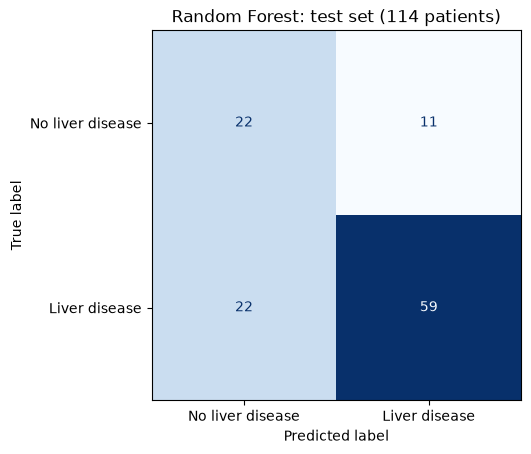

In [5]:
best_name, best_model, proba, test_metrics = test_best_model(
    cv_results, models, X_train, y_train, X_test, y_test, labels=["No liver disease", "Liver disease"]
)

In [6]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split

aucs = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    model = clone(best_model).fit(Xa, ya)          # fresh copy of the same pipeline
    aucs.append(roc_auc_score(yb, model.predict_proba(Xb)[:, 1]))

print("Test ROC-AUC on 10 different splits:", [round(a, 2) for a in aucs])
print(f"Average {pd.Series(aucs).mean():.3f}, lowest {min(aucs):.3f}, highest {max(aucs):.3f}")

Test ROC-AUC on 10 different splits: [0.74, 0.73, 0.78, 0.74, 0.79, 0.79, 0.7, 0.79, 0.76, 0.76]
Average 0.759, lowest 0.700, highest 0.792


In [7]:
risk_level_table(proba, y_test)

,patients,actually_had_disease
risk_level,,
Low,6,17%
Moderate,49,55%
High,59,90%


In [8]:
save_model(ROOT / "models", "liver", best_name, best_model, FEATURES, cv_results, test_metrics, notes={
    "dataset": "UCI ILPD (id 225), north-east Andhra Pradesh; exact duplicate rows removed",
    "target": "1 = liver patient (Selector 1), 0 = not (Selector 2)",
    "class_weight": "balanced (the 71% disease rate reflects hospital collection, not real life)",
    "feature_meaning": {
        "TB": "Total Bilirubin (mg/dL)", "DB": "Direct Bilirubin (mg/dL)", "Sgpt": "SGPT (U/L)",
        "Sgot": "SGOT (U/L)", "Alkphos": "Alkaline Phosphatase (U/L)", "TP": "Total Protein (g/dL)",
        "ALB": "Albumin (g/dL)", "A/G Ratio": "Albumin/Globulin ratio", "Age": "Age (years)",
        "Sex": "1 = male, 0 = female",
    },
    "repeated_split_test_roc_auc": {
        "average": round(float(pd.Series(aucs).mean()), 3),
        "lowest": round(min(aucs), 3),
        "highest": round(max(aucs), 3),
    },
    "limitation": "Weak, noisy dataset: liver values overlap heavily between groups and one test split "
                  "of ~115 patients varies a lot. Show this result as indicative only.",
})

Saved: liver_pipeline.joblib and liver_metrics.json


In [9]:
loaded = joblib.load(ROOT / "models" / "liver_pipeline.joblib")
samples = pd.DataFrame([
    {"TB": 4.5, "DB": 2.3, "Sgpt": 120, "Sgot": 150, "Alkphos": 400, "TP": 6.0, "ALB": 2.8,
     "A/G Ratio": 0.8, "Age": 50, "Sex": 1},
    {"TB": 0.7, "DB": 0.2, "Sgpt": 22, "Sgot": 25, "Alkphos": 180, "TP": 7.0, "ALB": 3.8,
     "A/G Ratio": 1.2, "Age": 35, "Sex": 0},
])
for name, p in zip(["Abnormal liver tests", "Normal liver tests"], loaded.predict_proba(samples)[:, 1]):
    print(f"{name}: probability {p:.2f} -> {risk_level(p)} risk")

Abnormal liver tests: probability 0.91 -> High risk
Normal liver tests: probability 0.26 -> Low risk
